# Laboratorio 1: Regresión en California

En este laboratorio deben hacer experimentos de regresión con el conjunto de datos "California Housing dataset".

Estudiarán el dataset, harán visualizaciones y seleccionarán atributos relevantes a mano.

Luego, entrenarán y evaluarán diferentes tipos de regresiones, buscando las configuraciones que mejores resultados den.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error


## Carga del Conjunto de Datos

Cargamos el conjunto de datos y vemos su contenido.

In [2]:
from sklearn.datasets import fetch_california_housing
X_california, y_california = fetch_california_housing(return_X_y=True, as_frame=True)
california = fetch_california_housing()

In [3]:
california.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [4]:
print(california['DESCR'])  # descripción del dataset
#california['feature_names'] # nombres de los atributos para cada columna de 'data'
#california['data']           # matriz con los datos de entrada (atributos)
#print(california['target']) # vector de valores a predecir

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [5]:
#limpieza de datos
## comentar o descomentar esta celda para filtrar los datos

california['data'].shape, california['target'].shape

q95 = np.quantile(california['target'], 0.95)
q01 = np.quantile(california['target'], 0.01)
mask = (california['target'] >= q01) & (california['target'] <= q95)

for col in X_california.columns:
    q95_col = np.quantile(X_california[col], 0.95)
    q01_col = np.quantile(X_california[col], 0.01)
    mask = mask & ((X_california[col] >= q01_col) & (X_california[col] <= q95_col))

# La variable 'mask' es un boolean array (o pandas Series) que indica qué filas del dataset cumplen con los criterios de filtrado.
# Primero, selecciona las filas cuyo valor objetivo ('target') está entre el percentil 1 y el 95 (quita outliers extremos).
# Luego, para cada columna de entrada, también filtra para quedarse solo con los valores entre el percentil 1 y 95 de esa columna.
# El resultado es que 'mask' es True solo para las filas que están dentro del rango central (sin outliers) en todas las variables.
# Así, al aplicar mask, se eliminan outliers tanto en la variable objetivo como en los atributos de entrada.
y_california = y_california[mask]
california['data'] = california['data'][mask]
california['target'] = california['target'][mask]

## División en Entrenamiento y Evaluación

Dividimos aleatoriamente los datos en 80% para entrenamiento y 20% para evaluación:

In [6]:
from sklearn.model_selection import train_test_split
X, y = california['data'], california['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42)
X_train.shape, X_test.shape

((11111, 8), (2778, 8))

In [7]:
y.shape

(13889,)

In [8]:
y_test.shape

(2778,)

## Ejercicio 1: Descripción de los Datos y la Tarea

Responda las siguientes preguntas:

1. ¿De qué se trata el conjunto de datos?
2. ¿Cuál es la variable objetivo que hay que predecir? ¿Qué significado tiene?
3. ¿Qué información (atributos) hay disponibles para hacer la predicción?
4. ¿Qué atributos imagina ud. que serán los más determinantes para la predicción?
5. ¿Qué problemas observa a priori en el conjunto de datos? ¿Observa posibles sesgos, riesgos, dilemas éticos, etc? Piense que los datos pueden ser utilizados para hacer predicciones futuras.

**No hace falta escribir código para responder estas preguntas.**

1. **El conjunto de datos es un reporte de características de casas en California y su relación con la población habitante obtenido de un censo estatal realizado en 1990. Cada fila del dataset representa un bloque de población definido como la menor unidad geográfica para la que la oficina de censos estadounidense reporta los datos. Estos bloques promedian las características sobre grupos de entre 600 y 3000 personas.**

2. **La variable objetivo es el valor medio de las casas en el distrito de California expresado en unidades de 100.000 USD.**

3. **Los atributos disponibles son:**

- `MedInc`:          **mediana del ingreso en el bloque**
- `HouseAge`:        **mediana de la antigüedad de las viviendas en el bloque**
- `AveRooms`:        **media de habitaciones por vivienda en el bloque**
- `AveBedrms`:       **media de dormitorios por vivienda en el bloque**  
- `Population`:      **población del bloque**  
- `AveOccup`:        **media de ocupantes por vivienda**
- `Latitude`:        **latitud del bloque**
- `Longitude`:       **longitud del bloque**

4. **Probablemente, los factores más determinantes para la predicción serán la edad media de las casas y el ingreso medio de la población. Intuitivamente, el número de habitaciones o ambientes no refleja necesariamente el valor de una vivienda si no se considera el tamaño o el estado general. En cambio, una mayor antigüedad podría relacionarse con viviendas menos modernas o en zonas más consolidadas, lo que influye en su precio. Además, es razonable pensar que en zonas con mayores ingresos, las propiedades tienden a tener un valor más alto..**

5. **Uno de los principales problemas del conjunto de datos es que se trabaja con valores ya promediados por bloque, lo cual dificulta saber qué tan representativos son, ya que se pierde información sobre la distribución interna de los datos. Además, hay variables como latitud y longitud que están agrupadas por zonas, lo que complica su análisis. Otro punto importante es que los datos provienen del censo de California de 1990, por lo que pueden no ser útiles para predecir precios actuales o en otras regiones. También se observa que algunas variables están demasiado correlacionadas, como “population” y “AveOccup”, lo que no aporta información nueva al modelo. En cuanto a posibles sesgos, no se observan dilemas éticos evidentes, ya que no hay demasiado detalle sobre la población en sí.**


## Ejercicio 2: Visualización de los Datos

1. Para cada atributo de entrada, haga una gráfica que muestre su relación con la variable objetivo.
2. Estudie las gráficas, identificando **a ojo** los atributos que a su criterio sean los más informativos para la predicción.
3. Para ud., ¿cuáles son esos atributos? Lístelos en orden de importancia.

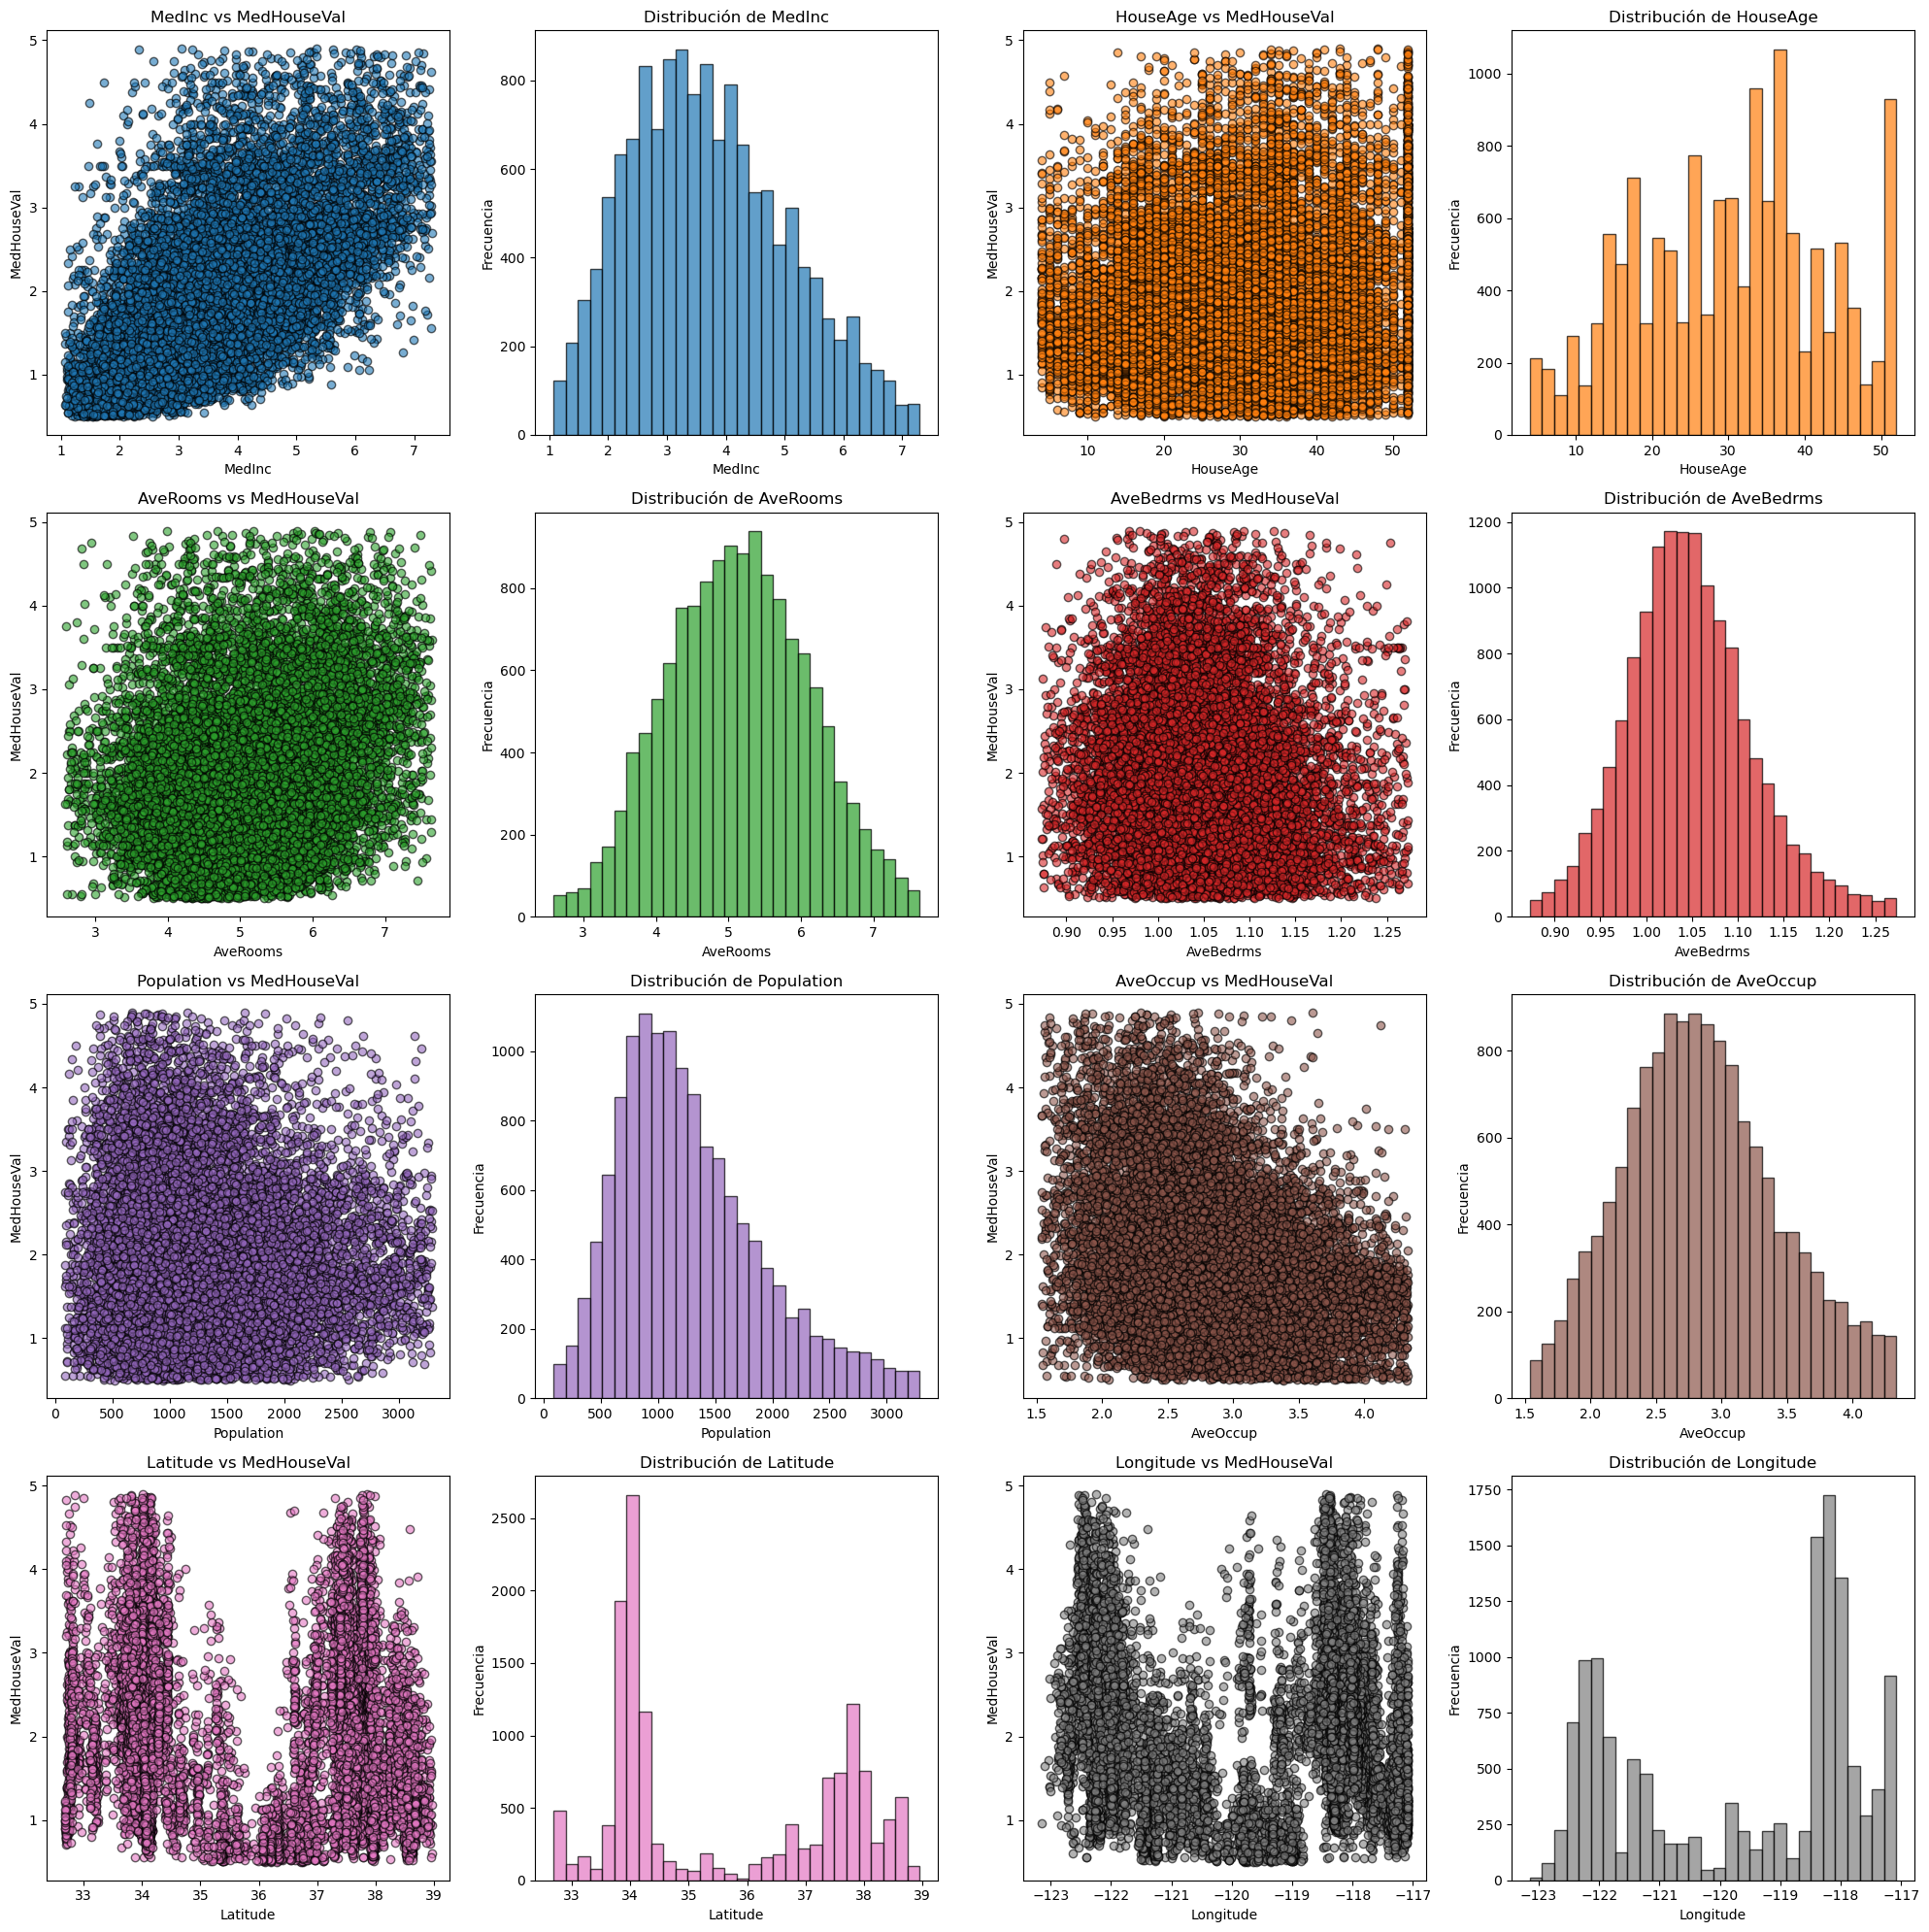

In [9]:
# 1. Resolver acá. Ayuda/ejemplo:
# feature = 'HouseAge'
# #selector = california['feature_names'].index(feature)
# selector = (np.array(california['feature_names']) == 'HouseAge')
# plt.scatter(X[:, selector], y, facecolor="dodgerblue", edgecolor="k", label="datos")
# plt.title(feature)
# plt.show()

#--------------------------------------------------------------------------------
features = california['feature_names']

fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(20, 20))
axes = axes.reshape(4, 4)
colors = plt.cm.tab10.colors  # 10 distinct colors

for idx, feature in enumerate(features):
    row = idx // 2
    col = (idx % 2) * 2  # 0 or 2

    # Scatter plot: feature vs target
    selector = (np.array(california['feature_names']) == feature)
    axes[row, col].scatter(X[:, selector], y, color=colors[idx % len(colors)], edgecolor="k", alpha=0.6)
    axes[row, col].set_title(f"{feature} vs MedHouseVal")
    axes[row, col].set_xlabel(feature)
    axes[row, col].set_ylabel("MedHouseVal")

    # Histogram: feature distribution
    axes[row, col + 1].hist(X[:, selector], bins=30, color=colors[idx % len(colors)], edgecolor="k", alpha=0.7)
    axes[row, col + 1].set_title(f"Distribución de {feature}")
    axes[row, col + 1].set_xlabel(feature)
    axes[row, col + 1].set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

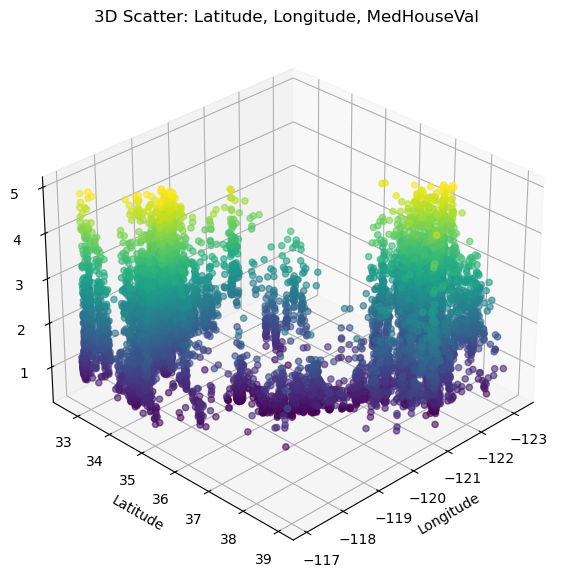

In [10]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
ax.view_init(elev=30, azim=45)  # Set an initial view angle (optional)

lat_idx = california['feature_names'].index('Latitude')
lon_idx = california['feature_names'].index('Longitude')

# List all available colormaps in matplotlib
#print(plt.colormaps())
ax.scatter(X[:, lon_idx], X[:, lat_idx], y, c=y, cmap='viridis', alpha=0.6)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_zlabel('MedHouseVal')
ax.set_title('3D Scatter: Latitude, Longitude, MedHouseVal')
plt.show()

2. **A partir del análisis visual de las gráficas, el atributo que parece ser más informativo para la predicción es el ingreso medio (MedIncome), ya que muestra una relación clara con el valor medio de las viviendas. Cabe mencionar que se realizó una limpieza del dataset para eliminar valores extremos, ya que dificultaban la visualización de las tendencias. También se observa una correlación negativa con variables como AveOccup y Population. En el caso de AveRooms, se aprecia una correlación positiva, aunque menos marcada que las anteriores. Por otro lado, con HouseAge la relación es menos evidente, y sería necesario eliminar aún más outliers para poder identificar mejor una posible tendencia.
Respecto a latitud y longitud, se decidió tratarlas como un par ordenado, ya que de ese modo permiten observar la distribución geográfica de los datos. En el gráfico correspondiente se distingue una clara clusterización en ciertas regiones que puede deberse a un sesgo en la captura de los datos, lo que repercutirá en el ingreso medio de las viviendas encuestadas así como en su valor. Aunque no se visualiza una correlación directa entre esta agrupación espacial y las medianas de estas características, se observa que en la región central del gráfico no encontramos viviendas de valores tan altos.**

3. **A ojo, los atributos que parecen más relevantes para la predicción, en orden de importancia, son: MedInc, AveOccup y AveRooms. En los gráficos se observa cierta tendencia lineal, especialmente en el caso del ingreso medio. Esto se puede corroborar con la matriz de correlación, cuya visualización mediante un heatmap muestra que MedInc es la variable con mayor correlación con el valor medio de la vivienda (0.59). Le siguen AveOccup con una correlación negativa de -0.33 y AveRooms con una correlación positiva más leve. Como observación adicional, se destaca que hay una correlación muy fuerte entre algunas variables, como AveBedrms y AveRooms, con un coeficiente de 0.85. Esto refuerza las conclusiones obtenidas previamente mediante la inspección visual.**

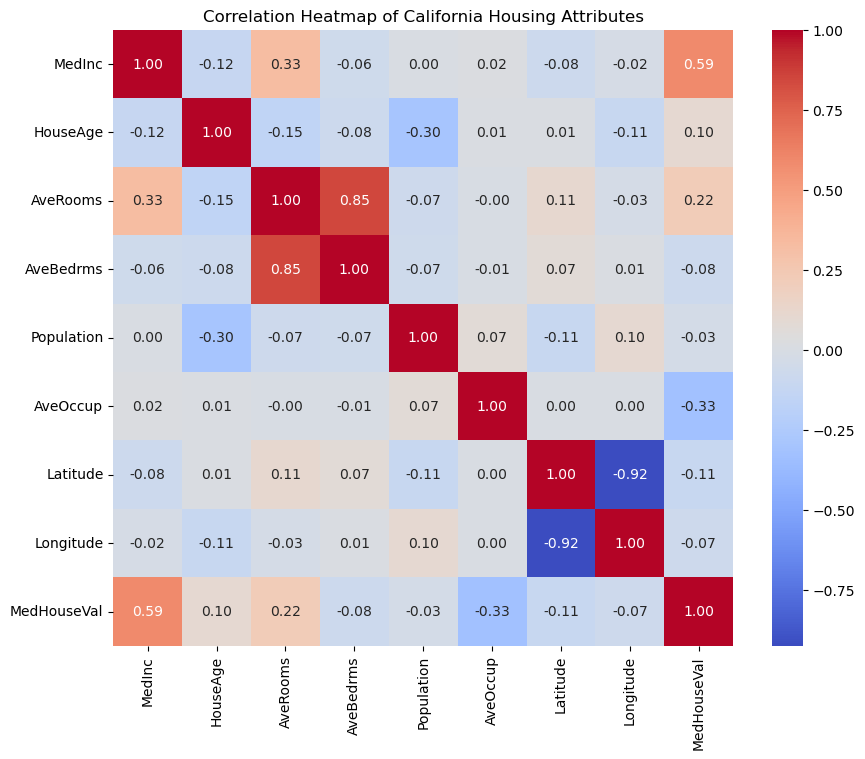

In [11]:
import seaborn as sns

full_data = X_california.copy()
full_data['MedHouseVal'] = y_california
corr_matrix = full_data.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap of California Housing Attributes")
plt.show()

## Ejercicio 3: Regresión Lineal

1. Seleccione **un solo atributo** que considere puede ser el más apropiado.
2. Instancie una regresión lineal de **scikit-learn**, y entrénela usando sólo el atributo seleccionado.
3. Evalúe, calculando error cuadrático medio para los conjuntos de entrenamiento y evaluación.
4. Grafique el modelo resultante, junto con los puntos de entrenamiento y evaluación.
5. Interprete el resultado, haciendo algún comentario sobre las cualidades del modelo obtenido.

**Observación:** Con algunos atributos se puede obtener un error en test menor a 50.

**1) Se elige MedInc, es decir, ingreso medio porque es el gráfico que muestra la distribución más lineal.** 

In [12]:
# 1. Resolver acá. Ayuda:
feature = 'MedInc'  # selecciono el atributo 'MedInc', se pueden probar todos cambiando solo desde aca
#selector = california['feature_names'].index(feature)
selector = (np.array(california['feature_names']) ==  feature)
X_train_f = X_train[:, selector]
X_test_f = X_test[:, selector]
X_train_f.shape, X_test_f.shape

((11111, 1), (2778, 1))

**2) Se instancia la regresión lineal, y se entrena sobre la feature seleccionada**

In [13]:
# 2. Instanciar y entrenar acá.
from sklearn.linear_model import LinearRegression
regresion = LinearRegression()
regresion.fit(X_train_f, y_train)

LinearRegression()

**3) Se realiza la predicción sobre conjuntos de testeo y entrenamiento**

In [14]:
# 3. Predecir y evaluar acá.

y_train_pred = regresion.predict(X_train_f)
y_test_pred = regresion.predict(X_test_f)

In [15]:
train_error = mean_squared_error(y_train, y_train_pred)
test_error = mean_squared_error(y_test, y_test_pred)
train_relative_error = np.mean(np.abs((y_train - y_train_pred) / y_train))
test_relative_error = np.mean(np.abs((y_test - y_test_pred) / y_test))
print(f'Error de entrenamiento: {train_error:f}')
print(f'Error de validación: {test_error:f}')
print(f'Error relativo de entrenamiento: {train_relative_error:.4f}')
print(f'Error relativo de validación: {test_relative_error:.4f}')

Error de entrenamiento: 0.549951
Error de validación: 0.559481
Error relativo de entrenamiento: 0.3520
Error relativo de validación: 0.3556


**4) Realizamos un gráfico del modelo vs los datos de entrenamiento y testeo**

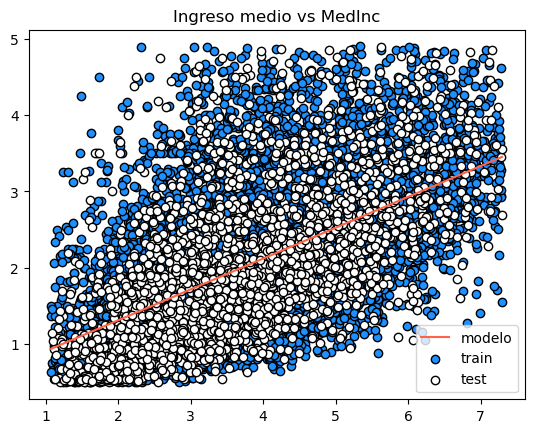

Coeficientes: [0.4034492]
Intercepto: 0.5086475098176144


In [16]:
# 4. Graficar acá. Ayuda:
x_start = min(np.min(X_train_f), np.min(X_test_f))
x_end = max(np.max(X_train_f), np.max(X_test_f))
x = np.linspace(x_start, x_end, 200).reshape(-1, 1)
plt.plot(x, regresion.predict(x), color="tomato", label="modelo")

plt.scatter(X_train_f, y_train, facecolor="dodgerblue", edgecolor="k", label="train")
plt.scatter(X_test_f, y_test, facecolor="white", edgecolor="k", label="test")
plt.title(f'Ingreso medio vs {feature}')
plt.legend()
plt.show()

print("Coeficientes:", regresion.coef_)
print("Intercepto:", regresion.intercept_)

5. **El modelo obtenido muestra una relación positiva entre el ingreso medio (MedInc) y el valor medio de la vivienda. Esta relación ya se anticipaba al observar una distribución aproximadamente lineal entre ambas variables. La recta ajustada refleja adecuadamente la tendencia general de los datos, aunque también es evidente la dispersión considerable en torno a ella, lo cual limita la capacidad predictiva del modelo cuando se usa un único atributo. Los errores cuadráticos medios en train (0.55) y test (0.56) son bastante similares, lo que sugiere que el modelo no está sobreajustado y generaliza de manera razonable. Sin embargo, el error relativo indica que aún queda una porción importante de la variabilidad sin explicar, lo que era esperable dado que solo se está utilizando una variable predictora. En resumen, se trata de un modelo simple pero consistente, que captura la tendencia principal sin sobreajustar, aunque con un poder explicativo limitado.**

## Ejercicio 4: Regresión Polinomial

En este ejercicio deben entrenar regresiones polinomiales de diferente complejidad, siempre usando **scikit-learn**.

Deben usar **el mismo atributo** seleccionado para el ejercicio anterior.

1. Para varios grados de polinomio, haga lo siguiente:
    1. Instancie y entrene una regresión polinomial.
    2. Prediga y calcule error en entrenamiento y evaluación. Imprima los valores.
    3. Guarde los errores en una lista.
2. Grafique las curvas de error en términos del grado del polinomio.
3. Interprete la curva, identificando el punto en que comienza a haber sobreajuste, si lo hay.
4. Seleccione el modelo que mejor funcione, y grafique el modelo conjuntamente con los puntos.
5. Interprete el resultado, haciendo algún comentario sobre las cualidades del modelo obtenido.

**Observación:** Con algunos atributos se pueden obtener errores en test menores a 40 e incluso a 35.

In [17]:
# 1. Resolver acá.

train_errors = []
test_errors = []

degrees = range(1, 11)

for degree in degrees:
    pf = PolynomialFeatures(degree=degree, include_bias=True)
    X_train_poly = pf.fit_transform(X_train_f)
    X_test_poly = pf.fit_transform(X_test_f)
    
    regresion_poly = LinearRegression()
    regresion_poly.fit(X_train_poly, y_train)

    y_train_pred_poly = regresion_poly.predict(X_train_poly)
    y_test_pred_poly = regresion_poly.predict(X_test_poly)

    train_error_poly = mean_squared_error(y_train, y_train_pred_poly)
    test_error_poly = mean_squared_error(y_test, y_test_pred_poly)

    train_errors.append(train_error_poly)
    test_errors.append(test_error_poly)
    
    print(f'Grado {degree}: Error absoluto entrenamiento: {train_error_poly:f}, Error absoluto validación: {test_error_poly:f}')



Grado 1: Error absoluto entrenamiento: 0.549951, Error absoluto validación: 0.559481
Grado 2: Error absoluto entrenamiento: 0.549815, Error absoluto validación: 0.559598
Grado 3: Error absoluto entrenamiento: 0.549282, Error absoluto validación: 0.559148
Grado 4: Error absoluto entrenamiento: 0.549105, Error absoluto validación: 0.558960
Grado 5: Error absoluto entrenamiento: 0.547727, Error absoluto validación: 0.558406
Grado 6: Error absoluto entrenamiento: 0.547725, Error absoluto validación: 0.558442
Grado 7: Error absoluto entrenamiento: 0.547713, Error absoluto validación: 0.558465
Grado 8: Error absoluto entrenamiento: 0.547701, Error absoluto validación: 0.558426
Grado 9: Error absoluto entrenamiento: 0.547661, Error absoluto validación: 0.558570
Grado 10: Error absoluto entrenamiento: 0.547661, Error absoluto validación: 0.558567


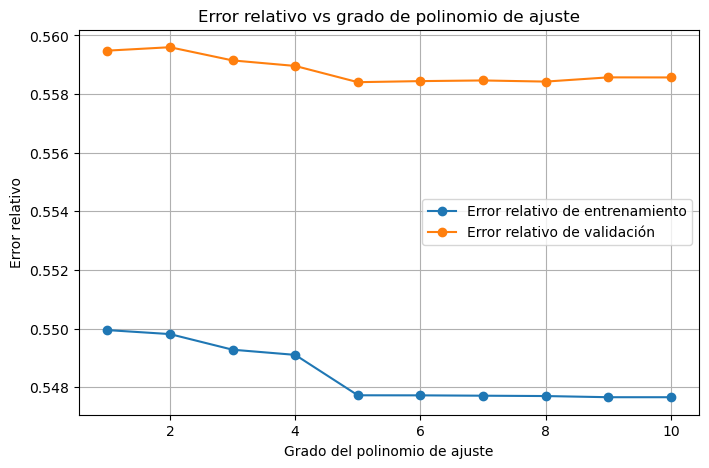

In [18]:
# 2. Graficar curvas de error acá.

plt.figure(figsize=(8, 5))
plt.plot(degrees, train_errors, marker='o', label='Error relativo de entrenamiento')
plt.plot(degrees, test_errors, marker='o', label='Error relativo de validación')
plt.xlabel('Grado del polinomio de ajuste')
plt.ylabel('Error relativo')
plt.title('Error relativo vs grado de polinomio de ajuste')
plt.legend()
plt.grid(True)
plt.show()

3. **La curva de error muestra que el error de entrenamiento disminuye gradualmente a medida que aumenta el grado del polinomio, mientras que el error de test baja hasta alrededor del grado 5 y a partir de ahí se mantiene prácticamente estable en lugar de volver a subir. Esto indica que, hasta el grado 10, no hay una señal clara de sobreajuste en los datos: el modelo más complejo no empeora la capacidad predictiva en el conjunto de validación, sino que simplemente deja de mejorar de forma notable pasados cierto grado. Por ello tiene sentido seleccionar un grado intermedio como el 5, ya que es donde el error de test se minimiza (o casi) antes de asentarse, sin incurrir en complejidad innecesaria.**

In [19]:
# 4. Reconstruir mejor modelo acá y graficar.

best_degree = np.argmin(test_errors) + 1  # degrees start from 1
print(f"El grado con menor error de test es: {best_degree}")

train_errors = []
test_errors = []
train_rel_errors = []
test_rel_errors = []
degrees = range(1, 11)

poly = PolynomialFeatures(degree=best_degree, include_bias=True)
X_train_poly = poly.fit_transform(X_train_f)
X_test_poly = poly.transform(X_test_f)

regresion_poly = LinearRegression()
regresion_poly.fit(X_train_poly, y_train)

y_train_pred_poly = regresion_poly.predict(X_train_poly)
y_test_pred_poly = regresion_poly.predict(X_test_poly)

train_error_poly = mean_squared_error(y_train, y_train_pred_poly)
test_error_poly = mean_squared_error(y_test, y_test_pred_poly)
train_rel_error_poly = np.mean(np.abs((y_train - y_train_pred_poly) / y_train))
test_rel_error_poly = np.mean(np.abs((y_test - y_test_pred_poly) / y_test))

train_errors.append(train_error_poly)
test_errors.append(test_error_poly)
train_rel_errors.append(train_rel_error_poly)
test_rel_errors.append(test_rel_error_poly)


El grado con menor error de test es: 5


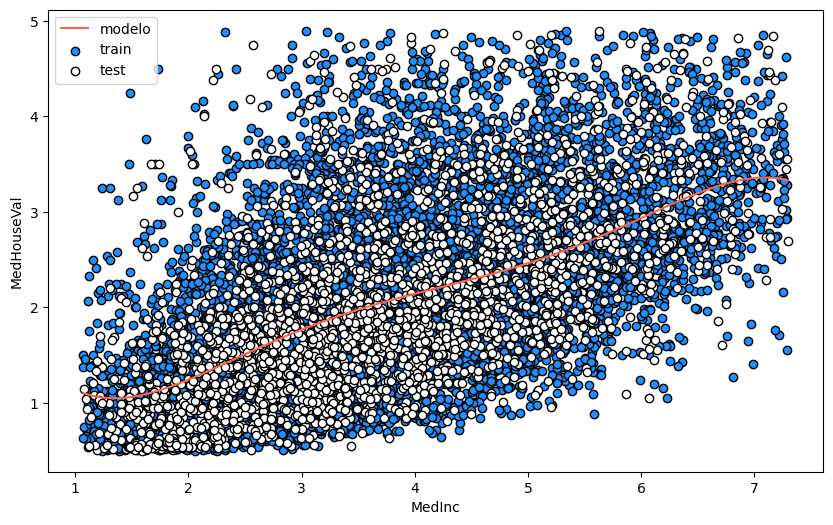

In [20]:
plt.figure(figsize=(10, 6))
x = np.linspace(x_start, x_end, 200).reshape(-1, 1)
x_poly = poly.transform(x)
plt.plot(x, regresion_poly.predict(x_poly), color="tomato", label=f"modelo")

plt.scatter(X_train_f, y_train, facecolor="dodgerblue", edgecolor="k", label="train")
plt.scatter(X_test_f, y_test, facecolor="white", edgecolor="k", label="test")
plt.xlabel('MedInc')
plt.ylabel('MedHouseVal')
plt.legend()
plt.show()

5. **El modelo polinómico de grado 5 muestra una curva suavemente creciente, sin oscilaciones abruptas, lo que indica que no se llegó al sobreajuste. Aunque se trata de un modelo más complejo que el lineal, el grado no es tan alto como para generar problemas numéricos ni para dificultar la interpretación. En cuanto al desempeño, si bien el modelo logra el error más bajo entre los evaluados, la diferencia con respecto al ajuste lineal no es muy significativa. Esto sugiere que gran parte de la relación entre MedInc y el valor medio de la vivienda ya se capta con una función lineal, y que el modelo de grado 5 refina esa tendencia sin introducir complejidad innecesaria.**

## Ejercicio 5: Regresión con más de un Atributo

En este ejercicio deben entrenar regresiones que toman más de un atributo de entrada.

1. Seleccione **dos o tres atributos** entre los más relevantes encontrados en el ejercicio 2.
2. Repita el ejercicio anterior, pero usando los atributos seleccionados. No hace falta graficar el modelo final.
3. Interprete el resultado y compare con los ejercicios anteriores. ¿Se obtuvieron mejores modelos? ¿Porqué?

1. **Se seleccionaron las variables AveOccup y AveRooms para agregar al modelo, ya que son los resultados más relevantes según lo estudiado en el punto 2.**

Grado 1: Error absoluto de entrenamiento: 0.306421, Error absoluto de validación: 0.309289
Grado 2: Error absoluto de entrenamiento: 0.292955, Error absoluto de validación: 0.294125
Grado 3: Error absoluto de entrenamiento: 0.286484, Error absoluto de validación: 0.288796
Grado 4: Error absoluto de entrenamiento: 0.283892, Error absoluto de validación: 0.288167
Grado 5: Error absoluto de entrenamiento: 0.281177, Error absoluto de validación: 0.286047
Grado 6: Error absoluto de entrenamiento: 0.280291, Error absoluto de validación: 0.286096
Grado 7: Error absoluto de entrenamiento: 0.279286, Error absoluto de validación: 0.285950
Grado 8: Error absoluto de entrenamiento: 0.278881, Error absoluto de validación: 0.287215
Grado 9: Error absoluto de entrenamiento: 0.277650, Error absoluto de validación: 0.289600
Grado 10: Error absoluto de entrenamiento: 0.276653, Error absoluto de validación: 0.291034


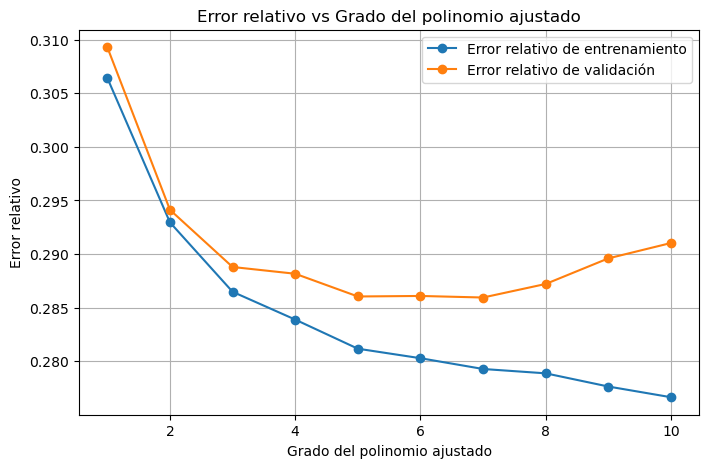

In [21]:
# 1. Resolver acá. Ayuda (con dos atributos):
selector = (np.array(california['feature_names']) == 'AveOccup') | (np.array(california['feature_names']) == 'AveRooms') | (np.array(california['feature_names']) == 'MedInc')

X_train_fs = X_train[:, selector]
X_test_fs = X_test[:, selector]
X_train_fs.shape, X_test_fs.shape

# 2. Resolver acá.


# Re-initialize error lists for this experiment
train_errors = []
test_errors = []
train_rel_errors = []
test_rel_errors = []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree, include_bias=True)
    X_train_poly = poly.fit_transform(X_train_fs)
    X_test_poly = poly.transform(X_test_fs)

    regresion_poly = LinearRegression()
    regresion_poly.fit(X_train_poly, y_train)

    y_train_pred_poly = regresion_poly.predict(X_train_poly)
    y_test_pred_poly = regresion_poly.predict(X_test_poly)

    train_error_poly = mean_squared_error(y_train, y_train_pred_poly)
    test_error_poly = mean_squared_error(y_test, y_test_pred_poly)
    train_rel_error_poly = np.mean(np.abs((y_train - y_train_pred_poly) / y_train))
    test_rel_error_poly = np.mean(np.abs((y_test - y_test_pred_poly) / y_test))

    train_errors.append(train_error_poly)
    test_errors.append(test_error_poly)
    train_rel_errors.append(train_rel_error_poly)
    test_rel_errors.append(test_rel_error_poly)
    
    print(f'Grado {degree}: Error absoluto de entrenamiento: {train_rel_error_poly:f}, Error absoluto de validación: {test_rel_error_poly:f}')

# Plot relative error vs degree
plt.figure(figsize=(8, 5))
plt.plot(degrees, train_rel_errors, marker='o', label='Error relativo de entrenamiento')
plt.plot(degrees, test_rel_errors, marker='o', label='Error relativo de validación')
plt.xlabel('Grado del polinomio ajustado')
plt.ylabel('Error relativo')
plt.title('Error relativo vs Grado del polinomio ajustado')
plt.legend()
plt.grid(True)
plt.show()

5.
**Al incorporar más atributos en el modelo, en este caso MedInc, AveOccup y AveRooms, se observa una mejora clara en el desempeño, medido mediante el error relativo de validación. Tiene sentido que agregar variables relevantes y no redundantes permita capturar mejor la variabilidad del valor medio de las viviendas, ya que se incorpora más información útil para la predicción. Por ejemplo, si bien atributos como la longitud y latitud no se utilizaron en este ejercicio, representan una potencial fuente de mejora si se los combina de manera adecuada, ya que podrían aportar contexto geográfico que, por sí solo, no se refleja en una sola variable. En este caso, se optó por variables con correlaciones visibles y significativas, y la combinación resultó en un modelo más ajustado.**
**En el gráfico se ve que el error relativo de entrenamiento disminuye continuamente con el grado del polinomio, mientras que el error de validación se estabiliza en torno al grado 5 y luego comienza a aumentar, lo que indica que el sobreajuste aparece a partir del grado 6. El valor mínimo del error relativo de testeo (0.286) se alcanza justo antes de este punto, lo cual confirma que ese grado ofrece el mejor equilibrio entre ajuste y capacidad de generalización. Además, se observa que las curvas de entrenamiento y validación se mantienen bastante cercanas hasta ese punto, lo que sugiere que el modelo generaliza bien y no depende excesivamente de los datos con los que fue entrenado.**